# Paper-informed CNN-LSTM: charging comparison and discharge diagnostic

Source: [Ma et al., Sustainability 17, 4014](sustainability-17-04014-v2.pdf).
Read pages 6, 8–10, 12, 14–16. The local PDF was extracted to `sustainability_paper_text.txt`.

| Setting | Paper | This notebook |
|---|---|---|
| Cells | CS2, nominal 1.1 Ah | Available CX2, validated 1.35 Ah labels |
| Inputs | H1 time at minimum discharge voltage; H2 mean discharge time; H3 mean discharge voltage | Both original five charging features and a separate explicit H1–H3 approximation |
| Split | Train CS2_34/36; test CS2_33/35 | Existing cell-disjoint train/validation/test, unchanged |
| CNN | Three convolution/pooling stages; dimensions 3×3, 5×4, 9×32 | Serial temporal Conv1d kernels 3/5/9, channels 3/4/32, ReLU and same-length max pooling |
| LSTM | Two layers shown, hidden size 256 | Two layers, 256 units |
| Outliers | K-means; complete rejection decision rule not specified | No target filtering or smoothing; validated original rows |

**This is an adaptation, not an exact reproduction.** The paper does not specify window length,
optimizer, learning rate, dropout rate, normalization or reproducible outlier rejection thresholds.
Figure 10 is ambiguous about convolution connectivity and displays softmax, while the text
specifies regression. Here we use serial stages and a linear regression head.

Engineering improvements beyond the paper: training-only target standardization, a linear
skip from the current features, validation-based learning-rate reduction, checkpointing and
early stopping. The skip lets the CNN-LSTM learn nonlinear temporal corrections to a direct estimate.
No hyperparameters or seeds are selected using the test set.

**Availability:** the charging experiment estimates SOH after charging. The discharge experiment
requires the completed same-cycle discharge. At constant current, duration is closely related to
the discharge capacity defining SOH. Its error is not an improvement at the charging prediction cutoff.
Neither experiment forecasts future SOH. Previously examined validation/test cells are not a fresh benchmark.


In [1]:
from pathlib import Path
import json, random, time, copy
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from torch import nn
from torch.utils.data import TensorDataset, DataLoader
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

ROOT = Path.cwd()
if not (ROOT / "pre processed ready to use data").exists():
    raise FileNotFoundError("Run this notebook from the Battery_Soh project root")
DATA_DIR = ROOT / "pre processed ready to use data"
OUTPUT_DIR = DATA_DIR.parent / "cnn_lstm_paper_informed_results"
OUTPUT_DIR.mkdir(exist_ok=True, parents=True)
FEATURES = ['cc_duration_s','cv_duration_s','dva_peak','ic_peak_voltage','ic_peak_width']
TARGET = 'soh'
SEQ_LEN=12
EPOCHS=150
BATCH_SIZE=128
LR=1e-3
PATIENCE=30
SEEDS=[42,123,2026]
DEVICE=torch.device('cuda' if torch.cuda.is_available() else 'cpu')
torch.set_num_threads(min(4, torch.get_num_threads()))
print('Device:', DEVICE, torch.cuda.get_device_name(0) if torch.cuda.is_available() else '')
for name in ['train.csv','validation.csv','test.csv']:
    assert (DATA_DIR/name).exists(), f'Missing {DATA_DIR/name}'


Device: cuda NVIDIA GeForce RTX 4050 Laptop GPU


In [2]:
train=pd.read_csv(DATA_DIR/'train.csv')
val=pd.read_csv(DATA_DIR/'validation.csv')
test=pd.read_csv(DATA_DIR/'test.csv')
for frame, name in [(train,'train'),(val,'validation'),(test,'test')]:
    missing=set(FEATURES+['battery','cycle_ordinal','cycle_start','source_identifiers',TARGET])-set(frame.columns)
    if missing: raise ValueError(f'{name} missing columns: {missing}')
    if not np.isfinite(frame[FEATURES+[TARGET]].to_numpy(dtype=float)).all(): raise ValueError(f'{name} contains missing inputs or targets')
    if frame.duplicated(['battery','cycle_ordinal']).any(): raise ValueError(f'{name} has duplicate battery/cycle IDs')
    print(name, frame.shape, sorted(frame.battery.unique()))
assert set(train.battery).isdisjoint(val.battery)
assert set(train.battery).isdisjoint(test.battery)
assert set(val.battery).isdisjoint(test.battery)


base_frames = {'train':train.copy(), 'validation':val.copy(), 'test':test.copy()}
BASE_OUTPUT = OUTPUT_DIR
CHARGING_FEATURES = FEATURES.copy()
DISCHARGE_FEATURES = ['h1_min_voltage_time_s','h2_mean_discharge_time_s','h3_mean_discharge_voltage_v']
feature_path = BASE_OUTPUT/'discharge_features.csv'
if not feature_path.exists():
    raise FileNotFoundError('Run extract_paper_discharge_features.py with the base Anaconda Python first')
discharge_table = pd.read_csv(feature_path)
assert discharge_table.cycle_id.is_unique
print('Extracted discharge features:',discharge_table[DISCHARGE_FEATURES].notna().all(axis=1).sum())


train (7790, 13) ['CX2_16', 'CX2_33', 'CX2_34', 'CX2_35', 'CX2_37']
validation (1743, 13) ['CX2_36']
test (1477, 13) ['CX2_38']


Extracted discharge features: 10839


In [3]:
def make_windows(frame, seq_len=SEQ_LEN):
    xs,ys,meta=[],[],[]
    for battery, part in frame.groupby('battery'):
        part=part.sort_values('cycle_ordinal').reset_index(drop=True)
        cycles=part.cycle_ordinal.to_numpy()
        values=scaler.transform(part[FEATURES].to_numpy(dtype=np.float64)).astype(np.float32)
        targets=part[TARGET].to_numpy(dtype=np.float32)
        # Divide into maximal uninterrupted runs of consecutive ordinal IDs
        times=pd.to_datetime(part.cycle_start, errors='raise')
        if times.isna().any() or part.source_identifiers.isna().any():
            raise ValueError('Missing acquisition metadata')
        source=part.source_identifiers.to_numpy()
        breaks=(np.diff(cycles)!=1) | (source[1:]!=source[:-1]) | (np.diff(times.to_numpy())<=np.timedelta64(0,'s'))
        boundaries=np.r_[0, np.flatnonzero(breaks)+1, len(part)]
        for a,z in zip(boundaries[:-1],boundaries[1:]):
            for end in range(a+seq_len-1,z):
                start=end-seq_len+1
                xs.append(values[start:end+1]); ys.append(targets[end])
                meta.append({'battery':battery,'cycle_ordinal':int(cycles[end]),'soh':float(targets[end]),'cycle_start':str(part.cycle_start.iloc[end]),'window_start_cycle':int(cycles[start])})
    if not xs: raise ValueError('No full contiguous windows. Reduce SEQ_LEN or inspect cycle ordinals.')
    return np.stack(xs),np.array(ys,dtype=np.float32),pd.DataFrame(meta)



## Explicit H1–H3 definitions

The paper names H1–H3 without extraction equations. We define elapsed discharge time
as recorder `test_s - first_test_s + first_step_s`; H1 is its value at minimum measured
discharge voltage, H2 is its sample mean, and H3 is sample-mean voltage. These choices
depend on sampling cadence and are documented approximations. We accept a single
recorded discharge step with at least five samples and strictly increasing elapsed time.
Cycles with unresolved sources or unavailable features are excluded and counted.
Targets are the existing validated labels, never recalculated from these predictors.


In [4]:
class PaperInspiredCNNLSTM(nn.Module):
    def __init__(self,n_features=None,hidden=256,dropout=0.1):
        super().__init__()
        n_features = len(FEATURES) if n_features is None else n_features
        layers=[]; channels=n_features
        for kernel,out_channels in [(3,3),(5,4),(9,32)]:
            layers += [nn.Conv1d(channels,out_channels,kernel,padding=kernel//2),
                       nn.ReLU(), nn.MaxPool1d(3,stride=1,padding=1)]
            channels=out_channels
        self.cnn=nn.Sequential(*layers)
        self.lstm=nn.LSTM(32,hidden,num_layers=2,dropout=dropout,batch_first=True)
        self.head=nn.Sequential(nn.Dropout(dropout),nn.Linear(hidden,1))
        self.skip=nn.Linear(n_features,1)
        self.register_buffer('target_mean',torch.tensor(float(train.soh.mean())))
        self.register_buffer('target_std',torch.tensor(float(train.soh.std(ddof=0))))
    def forward(self,x):
        z=self.cnn(x.transpose(1,2)).transpose(1,2)
        z,_=self.lstm(z)
        normalized=self.head(z[:,-1,:])+self.skip(x[:,-1,:])
        return self.target_mean+self.target_std*normalized.squeeze(-1)


In [5]:
def metrics(y,p):
    y=np.asarray(y);p=np.asarray(p)
    return {'mae_pp':float(mean_absolute_error(y,p)*100),
            'rmse_pp':float(np.sqrt(mean_squared_error(y,p))*100),
            'mbe_pp':float(np.mean(p-y)*100),
            'mape_percent':float(np.mean(np.abs((p-y)/np.maximum(np.abs(y),1e-8)))*100),
            'r2':float(r2_score(y,p))}

def predict(model,X,batch=512):
    model.eval(); out=[]
    loader=DataLoader(torch.from_numpy(X),batch_size=batch)
    with torch.no_grad():
        for xx in loader: out.append(model(xx.to(DEVICE)).cpu().numpy())
    return np.concatenate(out)

def train_one(seed):
    random.seed(seed);np.random.seed(seed);torch.manual_seed(seed)
    if torch.cuda.is_available():torch.cuda.manual_seed_all(seed)
    net=PaperInspiredCNNLSTM(n_features=len(FEATURES)).to(DEVICE)
    opt=torch.optim.AdamW(net.parameters(),lr=LR,weight_decay=1e-4)
    loss_fn=lambda pred,true: torch.mean(((pred-true)/net.target_std)**2)
    scheduler=torch.optim.lr_scheduler.ReduceLROnPlateau(opt,mode='min',factor=0.5,patience=7,min_lr=1e-5)
    loader=DataLoader(TensorDataset(torch.from_numpy(Xtr),torch.from_numpy(ytr)),
                      batch_size=BATCH_SIZE,shuffle=True)
    best=float('inf');best_state=None;bad=0;history=[];start=time.time()
    for epoch in range(1,EPOCHS+1):
        net.train();total=0.;count=0
        for xb,yb in loader:
            xb,yb=xb.to(DEVICE),yb.to(DEVICE)
            opt.zero_grad(set_to_none=True)
            loss=loss_fn(net(xb),yb)
            loss.backward();torch.nn.utils.clip_grad_norm_(net.parameters(),1.0)
            opt.step();total+=loss.item()*len(yb);count+=len(yb)
        val_pred=predict(net,Xva)
        val_mse=float(np.mean((val_pred-yva)**2))
        print(f'Seed {seed} epoch {epoch} validation RMSE {np.sqrt(val_mse)*100:.4f} pp', flush=True)
        history.append({'epoch':epoch,'train_mse':total/count*float(net.target_std)**2,'val_mse':val_mse,'lr':opt.param_groups[0]['lr']})
        scheduler.step(val_mse)
        if val_mse<best-1e-8:
            best=val_mse;best_state=copy.deepcopy(net.state_dict());bad=0
        else:bad+=1
        if epoch==1 or epoch%10==0 or bad>=PATIENCE:
            print(f'Seed {seed} epoch {epoch:3d} train MSE {total/count:.6f} val MSE {val_mse:.6f}')
        if bad>=PATIENCE:break
    net.load_state_dict(best_state)
    torch.save({'model_state':net.state_dict(),'features':FEATURES,'seq_len':SEQ_LEN,
                'seed':seed,'architecture':'paper-informed serial CNN LSTM with current-feature linear skip','scaler_mean':scaler.mean_.tolist(),'scaler_scale':scaler.scale_.tolist(),'best_epoch':int(np.argmin([h['val_mse'] for h in history])+1)},OUTPUT_DIR/f'cnn_lstm_seed{seed}.pt')
    pd.DataFrame(history).to_csv(OUTPUT_DIR/f'history_seed{seed}.csv',index=False)
    rows=[]
    for split,X,y,meta in [('train',Xtr,ytr,mtr),('validation',Xva,yva,mva),('test',Xte,yte,mte)]:
        pred=predict(net,X);out=meta.copy();out['prediction']=pred;out['error']=pred-y
        out.to_csv(OUTPUT_DIR/f'predictions_{split}_seed{seed}.csv',index=False)
        rows.append({'seed':seed,'split':split,'epochs':len(history),
                     'training_seconds':round(time.time()-start,2),**metrics(y,pred)})
    return rows,history


,split,original_rows,feature_rows,windows
0,train,7790,7790,3639
1,validation,1743,1743,848
2,test,1477,1477,662


Seed 42 epoch 1 validation RMSE 1.8569 pp


Seed 42 epoch   1 train MSE 0.071134 val MSE 0.000345


Seed 42 epoch 2 validation RMSE 2.5439 pp


Seed 42 epoch 3 validation RMSE 1.6589 pp


Seed 42 epoch 4 validation RMSE 1.1460 pp


... (270 outputs left out)

Seed 2026 epoch 83 validation RMSE 0.8292 pp


Seed 2026 epoch 84 validation RMSE 0.8511 pp


Seed 2026 epoch 85 validation RMSE 0.8245 pp


Seed 2026 epoch  85 train MSE 0.001480 val MSE 0.000068


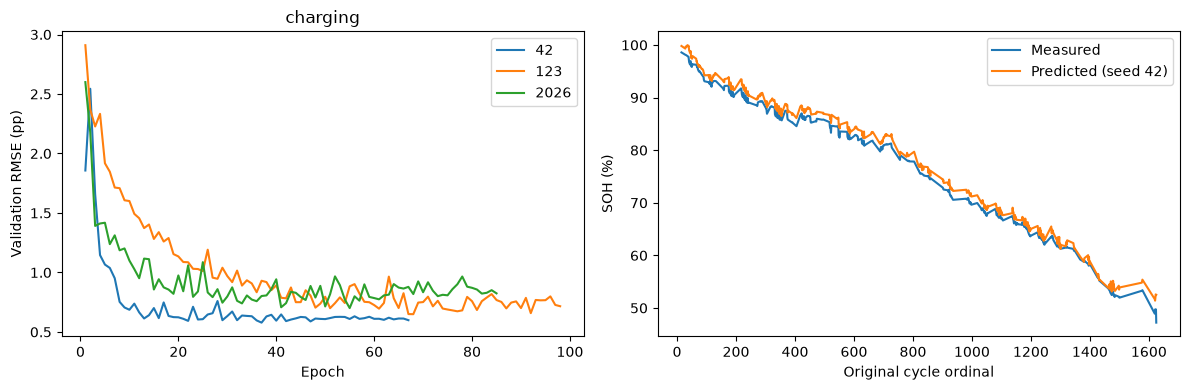

,split,original_rows,feature_rows,windows
0,train,7790,7677,3100
1,validation,1743,1704,655
2,test,1477,1458,574


Seed 42 epoch 1 validation RMSE 11.9769 pp


Seed 42 epoch   1 train MSE 0.877306 val MSE 0.014345


Seed 42 epoch 2 validation RMSE 9.2057 pp


Seed 42 epoch 3 validation RMSE 8.7605 pp


Seed 42 epoch 4 validation RMSE 8.3383 pp


... (328 outputs left out)

Seed 2026 epoch 65 validation RMSE 1.3313 pp


Seed 2026 epoch 66 validation RMSE 1.3474 pp


Seed 2026 epoch 67 validation RMSE 1.3699 pp


Seed 2026 epoch  67 train MSE 0.024130 val MSE 0.000188


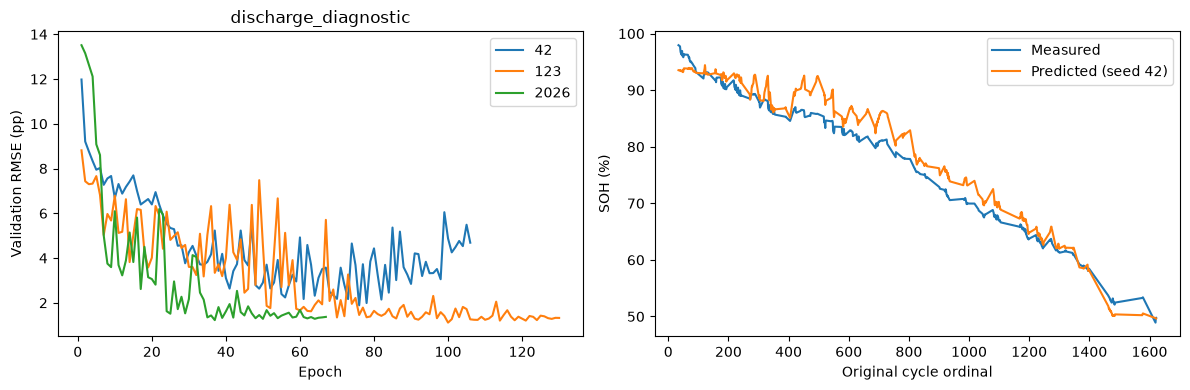

mae_pp             rmse_pp            \
                                     mean       std      mean       std   
experiment           split                                                
charging             test        1.508127  0.173965  1.590152  0.173762   
                     train       0.377000  0.023887  0.523082  0.034467   
                     validation  0.474986  0.047521  0.642809  0.061358   
discharge_diagnostic test        1.408115  0.915158  1.751120  0.964848   
                     train       1.399483  0.113094  2.829284  0.234907   
                     validation  0.937102  0.336215  1.409120  0.418115   

                                       r2            
                                     mean       std  
experiment           split                           
charging             test        0.983915  0.003394  
                     train       0.997650  0.000303  
                     validation  0.997174  0.000532  
discharge_diagnostic test        0.975422  0.026085  
                     train       0.931308  0.011121  
                     validation  0.985173  0.008969

In [6]:
combined=[]
for experiment, columns in [('charging',CHARGING_FEATURES),('discharge_diagnostic',DISCHARGE_FEATURES)]:
    FEATURES=columns
    OUTPUT_DIR=BASE_OUTPUT/experiment
    OUTPUT_DIR.mkdir(exist_ok=True)
    frames={}
    coverage=[]
    for split,base in base_frames.items():
        f=base.copy()
        if experiment=='discharge_diagnostic':
            f=f.merge(discharge_table[['cycle_id']+FEATURES],on='cycle_id',how='left',validate='one_to_one')
        good=np.isfinite(f[FEATURES].to_numpy(dtype=float)).all(axis=1)
        frames[split]=f.loc[good].copy()
        coverage.append({'split':split,'original_rows':len(f),'feature_rows':int(good.sum())})
    train,val,test=(frames[x] for x in ['train','validation','test'])
    scaler=StandardScaler().fit(train[FEATURES].to_numpy(dtype=float))
    (OUTPUT_DIR/'scaler.json').write_text(json.dumps({'features':FEATURES,'mean':scaler.mean_.tolist(),'scale':scaler.scale_.tolist()},indent=2))
    Xtr,ytr,mtr=make_windows(train); Xva,yva,mva=make_windows(val); Xte,yte,mte=make_windows(test)
    for row,n in zip(coverage,[len(ytr),len(yva),len(yte)]): row['windows']=n
    pd.DataFrame(coverage).to_csv(OUTPUT_DIR/'coverage.csv',index=False)
    display(pd.DataFrame(coverage))
    (OUTPUT_DIR/'config.json').write_text(json.dumps({'experiment':experiment,'features':FEATURES,'seeds':SEEDS,'epochs':EPOCHS,'patience':PATIENCE,'learning_rate':LR,'batch_size':BATCH_SIZE,'sequence_length':SEQ_LEN,'selection':'validation MSE only','outlier_filter':'none','prediction_cutoff':'charge end' if experiment=='charging' else 'discharge end'},indent=2))
    all_rows=[]; histories={}
    for seed in SEEDS:
        rows,hist=train_one(seed)
        all_rows.extend(rows);histories[seed]=hist
    results=pd.DataFrame(all_rows)
    results.to_csv(OUTPUT_DIR/'metrics_all_runs.csv',index=False)
    results['experiment']=experiment
    combined.append(results)
    fig,axs=plt.subplots(1,2,figsize=(12,4))
    for seed,h in histories.items():
        h=pd.DataFrame(h)
        axs[0].plot(h.epoch,np.sqrt(h.val_mse)*100,label=str(seed))
    axs[0].set(xlabel='Epoch',ylabel='Validation RMSE (pp)',title=experiment)
    axs[0].legend()
    p=pd.read_csv(OUTPUT_DIR/'predictions_test_seed42.csv')
    axs[1].plot(p.cycle_ordinal,p.soh*100,label='Measured')
    axs[1].plot(p.cycle_ordinal,p.prediction*100,label='Predicted (seed 42)')
    axs[1].set(xlabel='Original cycle ordinal',ylabel='SOH (%)');axs[1].legend()
    plt.tight_layout();plt.savefig(OUTPUT_DIR/'training_and_test.png',dpi=160);plt.show()
comparison=pd.concat(combined,ignore_index=True)
comparison.to_csv(BASE_OUTPUT/'metrics_all_experiments.csv',index=False)
display(comparison.groupby(['experiment','split'])[['mae_pp','rmse_pp','r2']].agg(['mean','std']))


In [7]:
# Compare charging models on exactly the same test target IDs for each seed.
matched=[]
for seed in SEEDS:
    a=pd.read_csv(ROOT/'cnn_lstm_original_features_results'/f'predictions_test_seed{seed}.csv')
    b=pd.read_csv(BASE_OUTPUT/'charging'/f'predictions_test_seed{seed}.csv')
    j=a.merge(b,on=['battery','cycle_ordinal'],suffixes=('_old','_new'),validate='one_to_one')
    assert len(j)==len(a)==len(b), 'Mismatched test coverage'
    assert np.allclose(j.soh_old,j.soh_new)
    for name in ['old','new']:
        matched.append({'seed':seed,'model':name,'n':len(j),**metrics(j.soh_old,j['prediction_'+name])})
matched=pd.DataFrame(matched)
matched.to_csv(BASE_OUTPUT/'matched_charging_comparison.csv',index=False)
display(matched)
print('Mean charging RMSE by model (pp):')
display(matched.groupby('model').rmse_pp.mean())


,seed,model,n,mae_pp,rmse_pp,mbe_pp,mape_percent,r2
0,42,old,662,0.837264,1.018092,0.767533,1.083098,0.993459
1,42,new,662,1.310509,1.392840,1.309373,1.705937,0.987757
2,123,old,662,0.945889,1.110119,0.930854,1.256582,0.992222
3,123,new,662,1.575725,1.657272,1.563456,2.054978,0.982666
4,2026,old,662,0.767751,0.904921,0.738806,0.993841,0.994832
5,2026,new,662,1.638148,1.720342,1.638148,2.234730,0.981322


Mean charging RMSE by model (pp):


model
new    1.590152
old    1.011044
Name: rmse_pp, dtype: float64

## How to read the results

Use `matched_charging_comparison.csv` to assess improvement at the original charging cutoff.
Compare the mean and spread across all three seeds, not just the best seed.
The discharge diagnostic measures a different information setting and must be reported separately.
The paper's 0.339 and 0.239 pp RMSE belong to CS2_33 and CS2_35, respectively (Tables 4–5),
not these CX2 test windows. No exact reproduction or guaranteed lower RMSE is claimed.
